In [3]:
import os
import glob
import cv2
import numpy as np
import matplotlib.pyplot as plt
from glob import glob
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Conv2DTranspose, concatenate
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.metrics import MeanIoU
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.metrics import precision_score, recall_score
import pandas as pd

2025-11-18 13:36:33.058776: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1763472993.241672      48 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1763472993.291183      48 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

In [4]:
import os
from glob import glob

data_folder = "/kaggle/input/wound-segmentation-images/data_wound_seg"

train_images = sorted(glob(os.path.join(data_folder, "train_images", "*.png")))
train_masks = sorted(glob(os.path.join(data_folder, "train_masks", "*.png")))

test_images = sorted(glob(os.path.join(data_folder, "test_images", "*.png")))
test_masks = sorted(glob(os.path.join(data_folder, "test_masks", "*.png")))

print(f"Total train images: {len(train_images)}\nTotal train masks: {len(train_masks)}")
print(f"Total test images: {len(test_images)}\nTotal test masks: {len(test_masks)}")


Total train images: 2208
Total train masks: 2208
Total test images: 552
Total test masks: 552


In [5]:
#check - class imbalance
def analyze_class_balance(mask_paths):
    total_pixels = 0
    wound_pixels = 0
    
    for mask_path in mask_paths:
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        mask_binary = (mask > 0).astype(np.uint8)  # Assuming wounds are non-zero
        
        total_pixels += mask.size
        wound_pixels += np.sum(mask_binary)
    
    wound_ratio = wound_pixels / total_pixels
    return wound_ratio

print("\n=== Class Balance Analysis ===")
train_wound_ratio = analyze_class_balance(train_masks)
test_wound_ratio = analyze_class_balance(test_masks)

print(f"Train set - Wound pixel ratio: {train_wound_ratio:.6f} ({train_wound_ratio*100:.4f}%)")
print(f"Test set - Wound pixel ratio: {test_wound_ratio:.6f} ({test_wound_ratio*100:.4f}%)")
print(f"Background pixel ratio: {1-train_wound_ratio:.6f} ({(1-train_wound_ratio)*100:.4f}%)")


=== Class Balance Analysis ===
Train set - Wound pixel ratio: 0.045851 (4.5851%)
Test set - Wound pixel ratio: 0.013409 (1.3409%)
Background pixel ratio: 0.954149 (95.4149%)


In [6]:
#Class weight calculation for wound and background classes
background_weight = 1.0
wound_weight = round((1-train_wound_ratio) / train_wound_ratio)

CLASS_WEIGHTS = {
    0: background_weight,  # Background class
    1: 10        # Wound class
}
pos_weight = wound_weight
print(f"Pos weight:{pos_weight}")

Pos weight:21


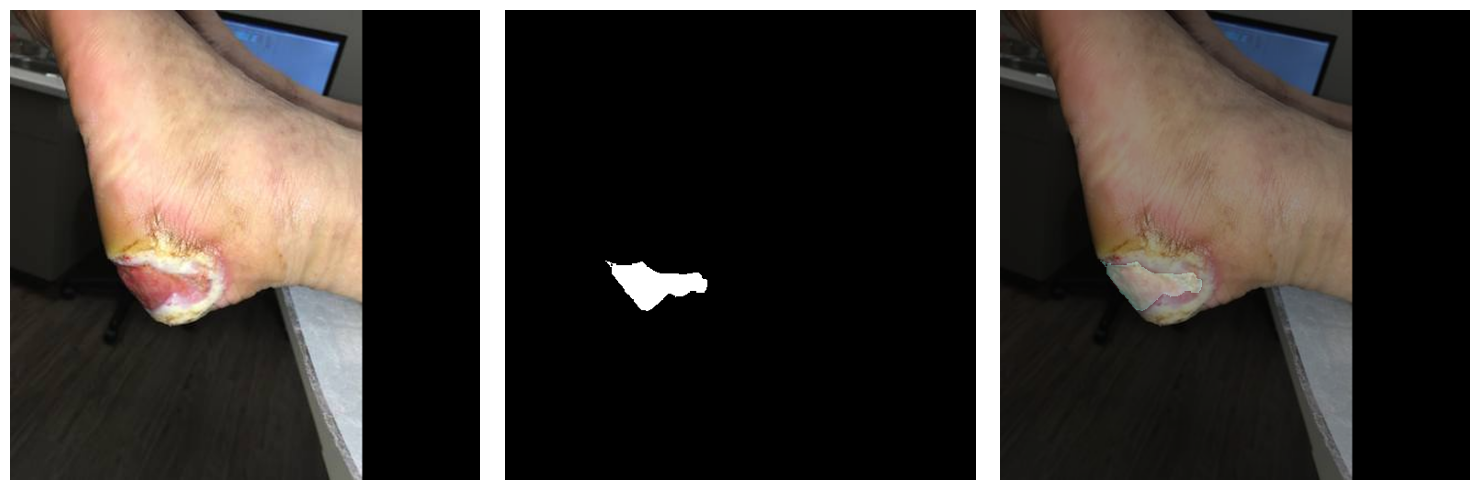

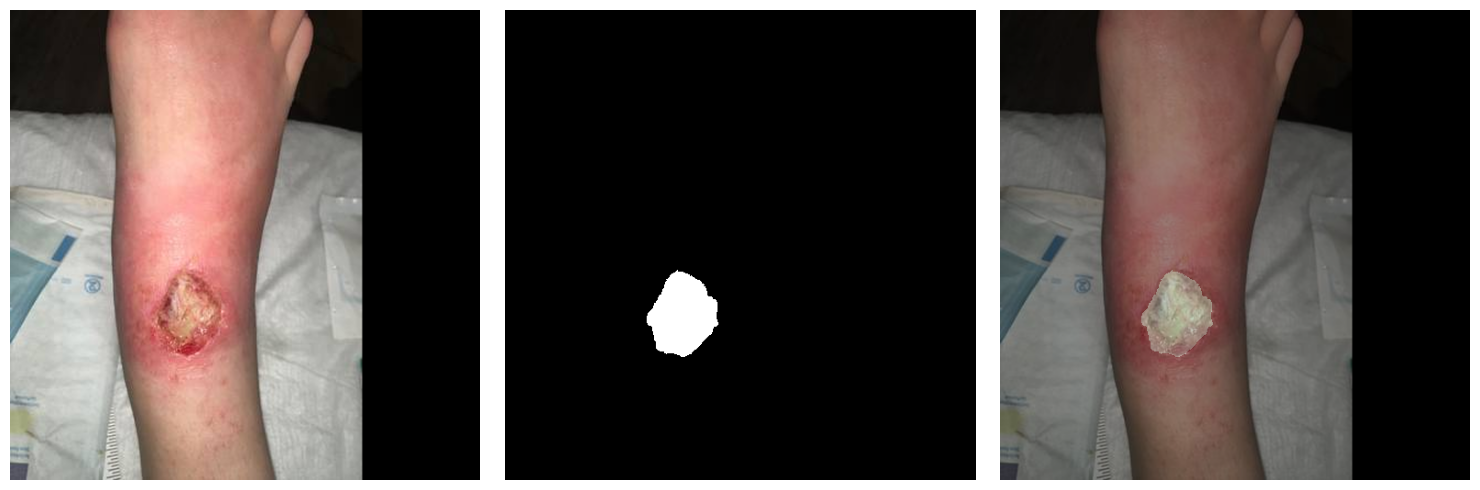

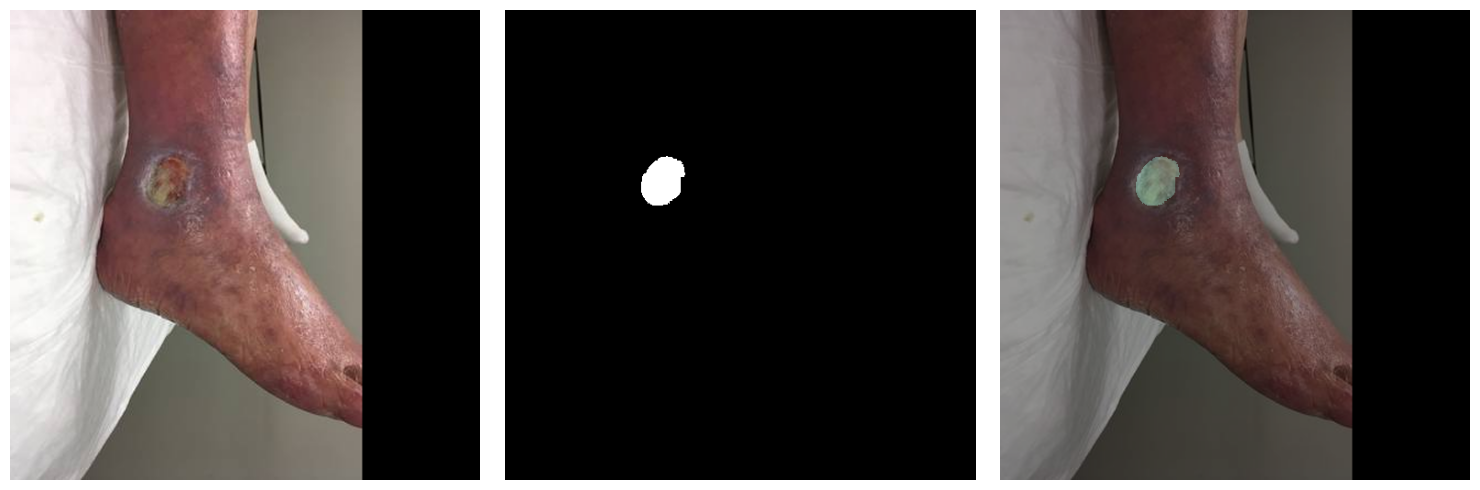

In [7]:
def get_colored_mask(image, mask_image,color = [103,193,173]):
    mask_image_gray = cv2.cvtColor(mask_image, cv2.COLOR_BGR2GRAY)
    mask = cv2.bitwise_and(mask_image, mask_image, mask=mask_image_gray)
    mask_coord = np.where(mask!=[0,0,0])
    mask[mask_coord[0],mask_coord[1],:]= color
    ret = cv2.addWeighted(image, 0.6, mask, 0.4, 0)
    return ret

trn_imgs = train_images[:3]
trn_msks = train_masks[:3]

for img_path,msk_path in zip(trn_imgs,trn_msks):
    img = cv2.imread(img_path)
    msk = cv2.imread(msk_path)

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(15,5))

    plt.subplot(131)
    plt.imshow(img)
    plt.yticks([])
    plt.xticks([])
    plt.box(False)

    plt.subplot(132)
    msk_gray = cv2.cvtColor(msk, cv2.COLOR_BGR2GRAY)
    plt.imshow(msk_gray, cmap='binary_r')
    plt.yticks([])
    plt.xticks([])
    plt.box(False)

    plt.subplot(133)
    plt.imshow(get_colored_mask(img, msk))
    plt.yticks([])
    plt.xticks([])
    plt.box(False)

    plt.tight_layout()
    plt.show()

In [8]:
import numpy as np
import cv2
from tensorflow.keras.utils import Sequence

# Constants for configuration
height = 256  # Target image height
width = 256   # Target image width
batch_size = 8   # Batch size for training

class DataGenerator(Sequence):
    """
    Custom data generator for loading and augmenting images and masks in batches.
    """

    def __init__(self, image_filenames, mask_filenames, batch_size, img_height, img_width, augment=False, shuffle=True):
        self.image_filenames = image_filenames
        self.mask_filenames = mask_filenames
        self.batch_size = batch_size
        self.img_height = img_height
        self.img_width = img_width
        self.augment = augment
        self.shuffle = shuffle
        self.indices = np.arange(len(self.image_filenames))
        self.on_epoch_end()  # Shuffle at initialization

    def __len__(self):
        """Returns the number of batches per epoch."""
        return int(np.ceil(len(self.image_filenames) / self.batch_size))

    def __getitem__(self, idx):
        """Generates one batch of data."""
        batch_indices = self.indices[idx * self.batch_size:(idx + 1) * self.batch_size]

        images, masks = [], []
        for i in batch_indices:
            img_path = self.image_filenames[i]
            mask_path = self.mask_filenames[i]

            img = self._load_and_preprocess_image(img_path)
            mask = self._load_and_preprocess_mask(mask_path)

            if self.augment:
                img, mask = self._apply_augmentation(img, mask)

            images.append(img)
            masks.append(mask)

        return np.array(images), np.array(masks)

    def on_epoch_end(self):
        """Shuffles dataset at the end of each epoch."""
        if self.shuffle:
            np.random.shuffle(self.indices)

    def _load_and_preprocess_image(self, img_path):
        """Loads and preprocesses an image."""
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (self.img_width, self.img_height))
        img = img / 255.0
        return img

    def _load_and_preprocess_mask(self, mask_path):
        """Loads and preprocesses a mask."""
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        mask = cv2.resize(mask, (self.img_width, self.img_height))
        mask = np.expand_dims(mask, axis=-1)
        mask = mask / 255.0
        mask = np.round(mask)  # Ensure binary mask
        return mask

    def _apply_augmentation(self, img, mask):
        """Applies random augmentation to an image and its mask."""
        # Random horizontal flip
        if np.random.rand() > 0.5:
            img = np.fliplr(img)
            mask = np.fliplr(mask)

        # Random vertical flip
        if np.random.rand() > 0.5:
            img = np.flipud(img)
            mask = np.flipud(mask)

        # Random rotation
        angle = np.random.randint(-15, 15)
        M = cv2.getRotationMatrix2D((self.img_width / 2, self.img_height / 2), angle, 1)
        img = cv2.warpAffine(img, M, (self.img_width, self.img_height))
        mask = cv2.warpAffine(mask, M, (self.img_width, self.img_height), flags=cv2.INTER_NEAREST)

        return img, mask


In [9]:
#trian and validation data set split
image_train, image_val, mask_train, mask_val = train_test_split(
    train_images, train_masks,
    test_size=0.2,
    random_state=42,
    shuffle=True
)

#Generate training and validation data
train_data = DataGenerator(image_train, mask_train, batch_size, height, width, augment=True) 
val_data = DataGenerator(image_val, mask_val, batch_size, height, width)

In [10]:
# ======================
# U-NET++ ARCHITECTURE
# ======================

IMG_SIZE = (height, width)

def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding='same', activation='relu')(x)
    x = layers.Conv2D(filters, 3, padding='same', activation='relu')(x)
    return x

def unet_plus_plus(input_shape=(*IMG_SIZE, 3)):
    inputs = layers.Input(shape=input_shape)

    # Encoder
    x00 = conv_block(inputs, 32)
    p0  = layers.MaxPooling2D()(x00)

    x10 = conv_block(p0, 64)
    p1  = layers.MaxPooling2D()(x10)

    x20 = conv_block(p1, 128)
    p2  = layers.MaxPooling2D()(x20)

    x30 = conv_block(p2, 256)
    p3  = layers.MaxPooling2D()(x30)

    x40 = conv_block(p3, 512)

    # Decoder with dense skip connections
    x01 = conv_block(layers.Concatenate()([
        layers.UpSampling2D()(x10), x00
    ]), 32)

    x11 = conv_block(layers.Concatenate()([
        layers.UpSampling2D()(x20), x10
    ]), 64)

    x02 = conv_block(layers.Concatenate()([
        layers.UpSampling2D()(x11), x00, x01
    ]), 32)

    x21 = conv_block(layers.Concatenate()([
        layers.UpSampling2D()(x30), x20
    ]), 128)

    x12 = conv_block(layers.Concatenate()([
        layers.UpSampling2D()(x21), x10, x11
    ]), 64)

    x03 = conv_block(layers.Concatenate()([
        layers.UpSampling2D()(x12), x00, x01, x02
    ]), 32)

    x31 = conv_block(layers.Concatenate()([
        layers.UpSampling2D()(x40), x30
    ]), 256)

    x22 = conv_block(layers.Concatenate()([
        layers.UpSampling2D()(x31), x20, x21
    ]), 128)

    x13 = conv_block(layers.Concatenate()([
        layers.UpSampling2D()(x22), x10, x11, x12
    ]), 64)

    x04 = conv_block(layers.Concatenate()([
        layers.UpSampling2D()(x13), x00, x01, x02, x03
    ]), 32)

    outputs = layers.Conv2D(1, 1, activation='sigmoid')(x04)

    return models.Model(inputs, outputs)

model = unet_plus_plus()
model.summary()

I0000 00:00:1763473036.228593      48 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15513 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 256,  │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 256, 256,  │      9,248 │ conv2d[0][0]      │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 128, 128,  │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 128,  │     36,928 │ conv2d_2[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 64, 64,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 64, 64,    │    147,584 │ conv2d_4[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 32, 32,    │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 32, 32,    │    295,168 │ max_pooling2d_2[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 32, 32,    │    590,080 │ conv2d_6[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 16, 16,    │          0 │ conv2d_7[0][0]    │
│ (MaxPooling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 16, 16,    │  1,180,160 │ max_pooling2d_3[… │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 16, 16,    │  2,359,808 │ conv2d_8[0][0]    │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_6     │ (None, 32, 32,    │          0 │ conv2d_9[0][0]    │
│ (UpSampling2D)      │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_6       │ (None, 32, 32,    │          0 │ up_sampling2d_6[

 Total params: 9,156,033 (34.93 MB)

 Trainable params: 9,156,033 (34.93 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
# Losses and metrics

def weighted_bce(y_true, y_pred):
    eps = 1e-7
    y_true = tf.cast(y_true, tf.float32)   # FIXED
    y_pred = tf.cast(y_pred, tf.float32)   # FIXED

    y_pred = tf.clip_by_value(y_pred, eps, 1 - eps)

    weight_pos = CLASS_WEIGHTS[1]
    weight_neg = CLASS_WEIGHTS[0]

    loss = - (
        weight_pos * y_true * tf.math.log(y_pred) +
        weight_neg * (1 - y_true) * tf.math.log(1 - y_pred)
    )
    return tf.reduce_mean(loss)


def dice_coef(y_true, y_pred, smooth=1e-6):
    y_true = tf.cast(y_true, tf.float32)   # FIXED
    y_pred = tf.cast(y_pred, tf.float32)   # FIXED

    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])

    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (
        tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth
    )


def iou_coef(y_true, y_pred, smooth=1e-6):
    y_true = tf.cast(y_true, tf.float32)   # FIXED
    y_pred = tf.cast(y_pred, tf.float32)   # FIXED

    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])

    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) - intersection
    return (intersection + smooth) / (union + smooth)

class DiceMetric(tf.keras.metrics.Metric):
    def __init__(self, name='dice', **kwargs):
        super().__init__(name=name, **kwargs)
        self.sum = self.add_weight(shape=(), name='sum', initializer='zeros')
        self.count = self.add_weight(shape=(), name='count', initializer='zeros')

    def update_state(self, y_true, y_pred, sample_weight=None):
        y_true = tf.cast(y_true, tf.float32)        # FIXED
        y_pred = tf.cast(y_pred > 0.5, tf.float32)  # FIXED
        val = dice_coef(y_true, y_pred)
        self.sum.assign_add(val)
        self.count.assign_add(1.0)

    def result(self):
        return self.sum / self.count

    def reset_states(self):
        self.sum.assign(0.0)
        self.count.assign(0.0)

class IoUMetric(tf.keras.metrics.Metric):
    def __init__(self, name='iou', **kwargs):
        super().__init__(name=name, **kwargs)
        self.sum = self.add_weight(shape=(), name='sum', initializer='zeros')
        self.count = self.add_weight(shape=(), name='count', initializer='zeros')

    def update_state(self, y_true, y_pred, sample_weight=None):
        y_true = tf.cast(y_true, tf.float32)        # FIXED
        y_pred = tf.cast(y_pred > 0.5, tf.float32)  # FIXED
        val = iou_coef(y_true, y_pred)
        self.sum.assign_add(val)
        self.count.assign_add(1.0)

    def result(self):
        return self.sum / self.count

    def reset_states(self):
        self.sum.assign(0.0)
        self.count.assign(0.0)


In [12]:
# Combined loss: weighted BCE + (1 - dice)
def dice_loss(y_true, y_pred):
    return 1 - dice_coef(y_true, y_pred)

def combined_loss(y_true, y_pred):
    return weighted_bce(y_true, y_pred) + dice_loss(y_true, y_pred)

In [13]:
#Compile model
model.compile(optimizer='adam', loss=combined_loss, metrics=[DiceMetric(), IoUMetric(), 'accuracy'])

In [14]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# Callbacks
early_stop = EarlyStopping(
    monitor='val_loss',
    mode='min',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',   # keep loss for LR scheduling
    mode='min',
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

checkpoint = ModelCheckpoint(
    'best_wound_unet_model.keras',
    monitor='val_loss',
    mode='min',
    save_best_only=True,
    verbose=1
)


# Compile
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=combined_loss,
    metrics=[DiceMetric(), IoUMetric(), 'accuracy']
)

# Train
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=100,
    callbacks=[early_stop, reduce_lr, checkpoint]
)

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/100


I0000 00:00:1763473047.107933     114 service.cc:148] XLA service 0x7907400021c0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1763473047.108609     114 service.cc:156]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1763473048.465659     114 cuda_dnn.cc:529] Loaded cuDNN version 90300
I0000 00:00:1763473072.345408     114 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


 10/221 ━━━━━━━━━━━━━━━━━━━━ 43s 208ms/step - accuracy: 0.4897 - dice: 0.1717 - iou: 0.0974 - loss: 1.9355

E0000 00:00:1763473077.565078     114 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1763473077.811296     114 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1763473078.442242     114 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1763473078.701321     114 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1763473078.967282     114 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


221/221 ━━━━━━━━━━━━━━━━━━━━ 0s 298ms/step - accuracy: 0.8672 - dice: 0.1777 - iou: 0.1072 - loss: 1.6757

E0000 00:00:1763473157.861964     114 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1763473158.105971     114 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1763473158.636077     114 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1763473158.891734     114 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.



Epoch 1: val_loss improved from inf to 1.20678, saving model to best_wound_unet_model.keras
221/221 ━━━━━━━━━━━━━━━━━━━━ 124s 406ms/step - accuracy: 0.8673 - dice: 0.1781 - iou: 0.1074 - loss: 1.6748 - val_accuracy: 0.9131 - val_dice: 0.4127 - val_iou: 0.2698 - val_loss: 1.2068 - learning_rate: 1.0000e-04
Epoch 2/100
221/221 ━━━━━━━━━━━━━━━━━━━━ 0s 184ms/step - accuracy: 0.9137 - dice: 0.4287 - iou: 0.2809 - loss: 1.1491
Epoch 2: val_loss improved from 1.20678 to 1.10997, saving model to best_wound_unet_model.keras
221/221 ━━━━━━━━━━━━━━━━━━━━ 47s 214ms/step - accuracy: 0.9137 - dice: 0.4287 - iou: 0.2809 - loss: 1.1492 - val_accuracy: 0.9131 - val_dice: 0.4407 - val_iou: 0.2909 - val_loss: 1.1100 - learning_rate: 1.0000e-04
Epoch 3/100
221/221 ━━━━━━━━━━━━━━━━━━━━ 0s 184ms/step - accuracy: 0.9222 - dice: 0.4454 - iou: 0.2996 - loss: 1.0982
Epoch 3: val_loss improved from 1.10997 to 1.09387, saving model to best_wound_unet_model.keras
221/221 ━━━━━━━━━━━━━━━━━━━━ 47s 213ms/step - accu

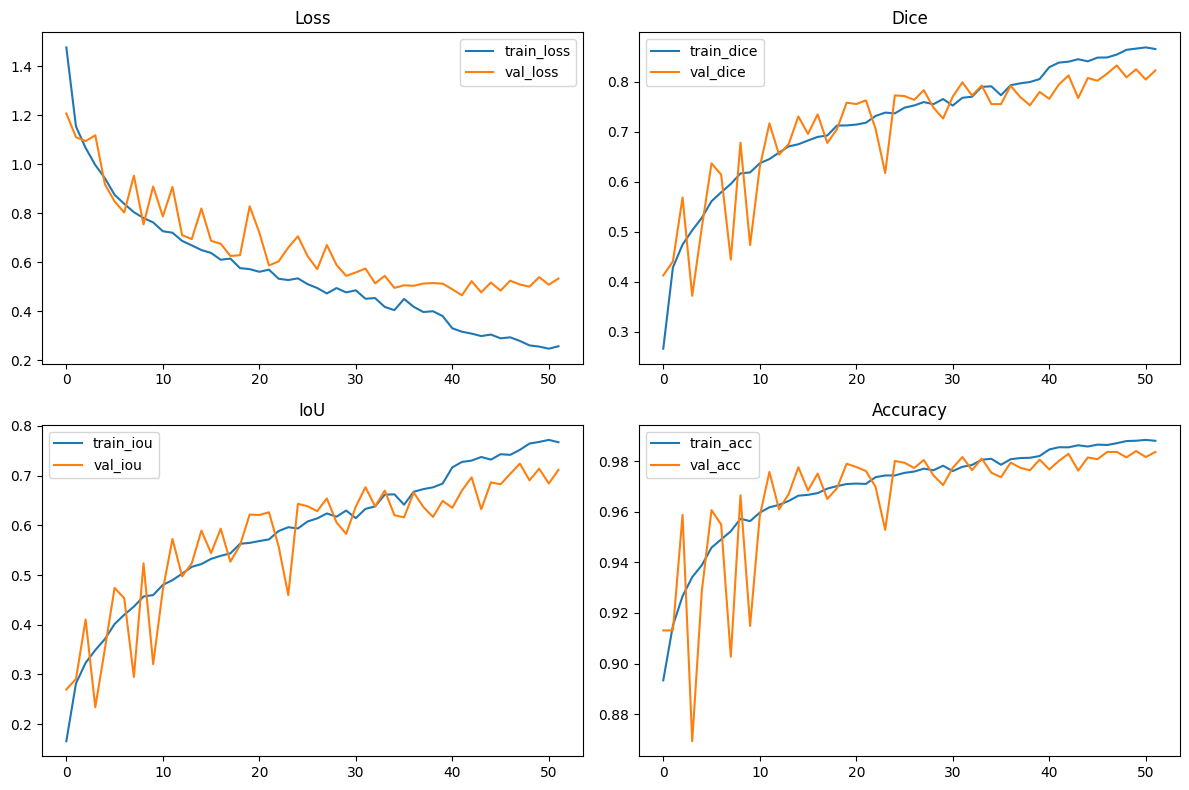

In [15]:
# Plot training & validation metrics
plt.figure(figsize=(12,8))
plt.subplot(2,2,1); plt.plot(history.history['loss'], label='train_loss'); plt.plot(history.history['val_loss'], label='val_loss'); plt.legend(); plt.title('Loss')
plt.subplot(2,2,2); plt.plot(history.history['dice'], label='train_dice'); plt.plot(history.history['val_dice'], label='val_dice'); plt.legend(); plt.title('Dice')
plt.subplot(2,2,3); plt.plot(history.history['iou'], label='train_iou'); plt.plot(history.history['val_iou'], label='val_iou'); plt.legend(); plt.title('IoU')
plt.subplot(2,2,4); plt.plot(history.history['accuracy'], label='train_acc'); plt.plot(history.history['val_accuracy'], label='val_acc'); plt.legend(); plt.title('Accuracy')
plt.tight_layout(); plt.show()

In [16]:
from tensorflow.keras.models import load_model

model = load_model(
    "best_wound_unet_model.keras",
    custom_objects={
        "DiceMetric": DiceMetric,
        "IoUMetric": IoUMetric,
        "combined_loss": combined_loss,
        "weighted_bce": weighted_bce,
        "dice_coef": dice_coef,
        "iou_coef": iou_coef
    }
)

In [17]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=combined_loss,
    metrics=[DiceMetric(name='dice'), IoUMetric(name='iou'), 'accuracy']
)

In [18]:
# Evaluate on test set and print results
test_data = DataGenerator(test_images, test_masks, batch_size, height, width)

results = model.evaluate(test_data, return_dict=True)
print(results)

69/69 ━━━━━━━━━━━━━━━━━━━━ 16s 189ms/step - accuracy: 0.9918 - dice: 0.7538 - iou: 0.6138 - loss: 0.3438
{'accuracy': 0.991984486579895, 'dice': 0.7478857636451721, 'iou': 0.6063387989997864, 'loss': 0.3504983186721802}
